In [1]:
from pathlib import Path
import json, inspect, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from astropy.stats import sigma_clip, sigma_clipped_stats, SigmaClip
from astropy.convolution import convolve_fft
from astropy.modeling import models, fitting
from photutils.aperture import CircularAnnulus, CircularAperture
from photutils.centroids import centroid_2dg
from photutils.background import Background2D, MedianBackground, StdBackgroundRMS
from photutils.segmentation import detect_sources, deblend_sources, make_2dgaussian_kernel, SourceCatalog
from scipy import ndimage
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")
DATA, RES, FIG = Path(".."), Path("results"), Path("figures")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})
mask = fits.getdata(RES / "mask.fits").astype(bool)
segm = fits.getdata(RES / "segmentation.fits").astype(np.int32)
cat = Table.read(RES / "catalogue.ecsv")
phot = Table.read(RES / "photometry.ecsv")
cal = Table.read(RES / "classified_catalogue.ecsv")
sdss = Table.read(DATA / "sdss_stars.csv", format="ascii.csv", comment="#")
ZP_R_MOSAIC = float(cal.meta["ZP_ap"])                # Cris's mosaic zero point (notebook 4)

R_AP, R_IN, R_OUT, R_OUT_STEP, R_OUT_MAX, MIN_SKY_PIX, SEG_GROW = 6.0, 15.0, 25.0, 10.0, 55.0, 60, 8
FLAG_MASKED, FLAG_NEIGHBOUR, FLAG_SKY, FLAG_NONPOSITIVE, FLAG_EDGE = 1, 2, 4, 8, 16
LN = 2.5 / np.log(10)

In [2]:
m = json.load(open(RES / "mosaic_to_tile_map.json")); CX, CY, ORDER = np.array(m["cx"]), np.array(m["cy"]), m["order"]


def design(x, y, order=ORDER, x0=1285, y0=2305):
    u, v = (np.asarray(x, float) - x0) / x0, (np.asarray(y, float) - y0) / y0
    return np.column_stack([u ** i * v ** j for i in range(order + 1) for j in range(order + 1 - i)])


def mosaic_to_tile(x, y):
    A = design(np.atleast_1d(x), np.atleast_1d(y)); return A @ CX, A @ CY


def local_scale(x, y, e=0.5):
    """tile pixels per mosaic pixel (linear) at mosaic position (x, y)"""
    x, y = np.atleast_1d(x).astype(float), np.atleast_1d(y).astype(float)
    a1, b1 = mosaic_to_tile(x + e, y); a0, b0 = mosaic_to_tile(x - e, y)
    a3, b3 = mosaic_to_tile(x, y + e); a2, b2 = mosaic_to_tile(x, y - e)
    return np.sqrt(np.abs((a1 - a0) * (b3 - b2) - (a3 - a2) * (b1 - b0)))


# inverse mapping (tile -> mosaic), fitted on a dense grid of the forward mapping
gy, gx = np.mgrid[-200:4811:40, -200:2771:40].astype(float)
GX, GY = mosaic_to_tile(gx.ravel(), gy.ravel())
A_inv = design(GX, GY, order=4, x0=2400, y0=2375)
ICX = np.linalg.lstsq(A_inv, gx.ravel(), rcond=None)[0]; ICY = np.linalg.lstsq(A_inv, gy.ravel(), rcond=None)[0]


def tile_to_mosaic(X, Y):
    A = design(np.atleast_1d(X), np.atleast_1d(Y), order=4, x0=2400, y0=2375); return A @ ICX, A @ ICY

In [3]:
def mosaic_layer_on_tile(layer, shape, fill):
    out = np.empty(shape, dtype=layer.dtype)
    for y0 in range(0, shape[0], 256):
        yy, xx = np.mgrid[y0:min(shape[0], y0 + 256), 0:shape[1]].astype(float)
        mx, my = tile_to_mosaic(xx.ravel(), yy.ravel())
        ix, iy = np.round(mx).astype(int), np.round(my).astype(int)
        inside = (ix >= 0) & (ix < layer.shape[1]) & (iy >= 0) & (iy < layer.shape[0])
        vals = np.full(ix.shape, fill, dtype=layer.dtype); vals[inside] = layer[iy[inside], ix[inside]]
        out[y0:y0 + yy.shape[0]] = vals.reshape(yy.shape)
    return out


def load_tile(band):
    d = fits.getdata(RES / f"tile_{band}_stitched.fits").astype(float)
    h = fits.getheader(RES / f"tile_{band}_stitched.fits")
    bad = ~np.isfinite(d)
    n_good_nb = ndimage.convolve((~bad).astype(int), np.ones((3, 3), int), mode="constant") - (~bad)
    fillable = bad & (n_good_nb >= 5)
    for y, x in zip(*np.where(fillable)):
        d[y, x] = np.nanmedian(d[max(0, y - 1):y + 2, max(0, x - 1):x + 2])
    still_bad = ~np.isfinite(d); d[still_bad] = 0.0
    return d, h, still_bad, int(fillable.sum())


tile_shape = fits.getdata(RES / "tile_r_stitched.fits").shape
mask_on_tile = mosaic_layer_on_tile(mask.astype(np.uint8), tile_shape, fill=1).astype(bool)
segm_on_tile = mosaic_layer_on_tile(segm, tile_shape, fill=0).astype(np.int64)
tiles = {}
for band in ("r", "i"):
    d, h, bad, n_filled = load_tile(band)
    tmask = mask_on_tile | ndimage.binary_dilation(bad, iterations=2)
    tiles[band] = {"data": d, "header": h, "mask": tmask, "segm": segm_on_tile,
                   "not_sky": tmask | ndimage.binary_dilation(segm_on_tile > 0, iterations=SEG_GROW)}
    print(f"{band} tile: filled {n_filled} isolated blank pixels")

r tile: filled 11331 isolated blank pixels


i tile: filled 11281 isolated blank pixels


In [4]:
def local_sky(t, x, y, r_in, r_out):
    widened = False
    while True:
        ann = CircularAnnulus((x, y), r_in, r_out).to_mask(method="center")
        vals = ann.cutout(t["data"], fill_value=np.nan)
        use = (ann.data > 0) & ~(ann.cutout(t["not_sky"].astype(float), fill_value=1.0) > 0) & np.isfinite(vals)
        if use.sum() >= MIN_SKY_PIX or r_out >= R_OUT_MAX:
            break
        r_out += R_OUT_STEP; widened = True
    if use.sum() < 5:
        return np.nan, np.nan, int(use.sum()), True
    c = sigma_clip(vals[use], sigma=3.0, maxiters=10, masked=False)
    return float(np.median(c)), float(np.std(c)), int(c.size), widened or use.sum() < MIN_SKY_PIX


def aperture_sum(t, x, y, r, sky, own_label):
    ap = CircularAperture((x, y), r).to_mask(method="exact"); w = ap.data
    v = ap.cutout(t["data"], fill_value=np.nan); msk = ap.cutout(t["mask"].astype(float), fill_value=1.0) > 0
    sg = ap.cutout(t["segm"], fill_value=0); off = bool(np.any(~np.isfinite(v) & (w > 0)))
    nb = (sg > 0) & (sg != own_label)
    v = np.where(msk | nb, sky, np.where(np.isfinite(v), v, sky))
    return float((w * (v - sky)).sum()), float(w.sum()), float((w * msk).sum() / w.sum()), float((w * (nb & ~msk)).sum() / w.sum()), off


def corr_factor(t, r_ap, n=3000, seed=0):
    """Correlated-noise factor from empty apertures (as notebook 3)."""
    rng = np.random.default_rng(seed); ny, nx = t["data"].shape
    clear = ~ndimage.binary_dilation(t["not_sky"], iterations=int(np.ceil(r_ap)) + 1)
    sums, exp = [], []; tries = 0
    while len(sums) < n and tries < 50 * n:
        tries += 1
        x, y = rng.uniform(R_OUT, nx - R_OUT), rng.uniform(R_OUT, ny - R_OUT)
        if not clear[int(y), int(x)]:
            continue
        s, s_std, _, bad = local_sky(t, x, y, R_IN, R_OUT)
        if bad or not np.isfinite(s):
            continue
        f, area, _, _, _ = aperture_sum(t, x, y, r_ap, s, -1)
        sums.append(f); exp.append(s_std * np.sqrt(area))
    sums = np.array(sums)
    return float(1.4826 * np.median(np.abs(sums - np.median(sums)))) / float(np.median(exp))

In [5]:
def recentroid(d, X, Y, half):
    a, b = int(round(X)), int(round(Y))
    cut = d[b - half:b + half + 1, a - half:a + half + 1]
    if cut.shape != (2 * half + 1, 2 * half + 1) or not np.isfinite(cut).all():
        return np.nan, np.nan
    cx, cy = centroid_2dg(cut - np.median(cut)); return cx + a - half, cy + b - half


def robust(v):
    v = np.asarray(v, float); med = float(np.median(v)); sig = float(1.4826 * np.median(np.abs(v - med)))
    return med, sig, float(1.2533 * sig / np.sqrt(len(v)))


def tile_zero_point(band, mag_col, mag_range=(16.5, 20.5), max_err=0.05):
    t = tiles[band]
    X0, Y0 = WCS(t["header"]).all_world2pix(sdss["ra"], sdss["dec"], 0)
    rows = []
    for k, (a, b) in enumerate(zip(X0, Y0)):
        X, Y = recentroid(t["data"], a, b, 8)
        if np.isfinite(X):
            X, Y = recentroid(t["data"], X, Y, 5)
        if not np.isfinite(X) or np.hypot(X - a, Y - b) > 3 or t["mask"][int(round(Y)), int(round(X))]:
            continue
        sc = float(local_scale(*tile_to_mosaic(X, Y))[0])
        s, _, _, bad = local_sky(t, X, Y, R_IN * sc, R_OUT * sc)
        f, _, fm, fn, off = aperture_sum(t, X, Y, R_AP * sc, s, int(t["segm"][int(round(Y)), int(round(X))]))
        if bad or fm > 0 or fn > 0.1 or off or not f > 0:
            continue
        rows.append((k, X, Y, f, float(sdss[mag_col][k]), float(sdss[mag_col.replace("Mag", "MagErr")][k]),
                     float(sdss["psfMag_r"][k] - sdss["psfMag_i"][k]), int(sdss["clean"][k])))
    st = Table(rows=rows, names=["idx", "X", "Y", "ap_flux", "m_sdss", "m_sdss_err", "r_minus_i", "clean"])
    st["zp"] = st["m_sdss"] + 2.5 * np.log10(st["ap_flux"])
    use = (st["clean"] == 1) & (st["m_sdss"] > mag_range[0]) & (st["m_sdss"] < mag_range[1]) & (st["m_sdss_err"] < max_err)
    keep = use.copy()
    for _ in range(5):
        med, sig, _ = robust(st["zp"][keep]); keep = use & (np.abs(st["zp"] - med) < 3 * max(sig, 0.01))
    med, sig, err = robust(st["zp"][keep]); st["used"] = keep
    ct, ccov = np.polyfit(st["r_minus_i"][keep], st["zp"][keep], 1, cov=True) if keep.sum() >= 4 else ([np.nan], np.full((2, 2), np.nan))
    return {"ZP": med, "err": err, "scatter": sig, "n": int(keep.sum()), "colour_term": float(ct[0]),
            "colour_term_err": float(np.sqrt(ccov[0, 0]))}, st


zp = {}; zp_stars = {}
for band in ("r", "i"):
    zp[band], zp_stars[band] = tile_zero_point(band, f"psfMag_{band}")
    z = zp[band]
    print(f"{band} tile: ZP = {z['ZP']:.3f} +- {z['err']:.3f} ({z['n']} stars, scatter {z['scatter']:.3f}); "
          f"colour dependence {z['colour_term']:+.3f} +- {z['colour_term_err']:.3f} per mag of r-i")

r tile: ZP = 31.627 +- 0.015 (24 stars, scatter 0.060); colour dependence +0.027 +- 0.022 per mag of r-i


i tile: ZP = 31.135 +- 0.010 (42 stars, scatter 0.050); colour dependence +0.046 +- 0.014 per mag of r-i


In [6]:
mos = fits.getdata(DATA / "mosaic.fits").astype(float)
Xs, Ys = WCS(tiles["r"]["header"]).all_world2pix(sdss["ra"], sdss["dec"], 0)
mx, my = tile_to_mosaic(Xs, Ys)
mos_t = {"data": mos, "mask": mask, "segm": segm.astype(np.int64), "not_sky": mask | ndimage.binary_dilation(segm > 0, iterations=SEG_GROW)}
rows = []
for k, (a, b) in enumerate(zip(mx, my)):
    if not (160 < a < mos.shape[1] - 160 and 160 < b < mos.shape[0] - 160) or mask[int(round(b)), int(round(a))]:
        continue
    cut = mos[int(round(b)) - 6:int(round(b)) + 7, int(round(a)) - 6:int(round(a)) + 7] - 3418.5
    if cut.max() < 150 or cut.max() > 0.8 * 36000 - 3418.5:
        continue
    cx_, cy_ = centroid_2dg(cut); xa, ya = cx_ + int(round(a)) - 6, cy_ + int(round(b)) - 6
    s, _, _, bad = local_sky(mos_t, xa, ya, R_IN, R_OUT)
    f, _, fm, fn, off = aperture_sum(mos_t, xa, ya, R_AP, s, int(segm[int(round(ya)), int(round(xa))]))
    r_s = float(sdss["psfMag_r"][k])
    if not bad and fn <= 0.1 and f > 0 and 17 < r_s < 20:
        rows.append((r_s + 2.5 * np.log10(f), float(sdss["psfMag_r"][k] - sdss["psfMag_i"][k])))
mz = np.array(rows)
ct_m, cc_m = np.polyfit(mz[:, 1], mz[:, 0], 1, cov=True)
print(f"mosaic r: colour dependence {ct_m[0]:+.3f} +- {np.sqrt(cc_m[0, 0]):.3f} per mag (from {len(mz)} stars); "
      f"zero point from these stars {np.median(mz[:, 0]):.3f} (Cris: {ZP_R_MOSAIC:.3f})")
net = ct_m[0] - zp["i"]["colour_term"]
print(f"net effect on r - i: {net:+.3f} +- {np.hypot(np.sqrt(cc_m[0, 0]), zp['i']['colour_term_err']):.3f} per mag -> negligible, no correction applied")

mosaic r: colour dependence +0.043 +- 0.035 per mag (from 17 stars); zero point from these stars 32.301 (Cris: 32.309)
net effect on r - i: -0.003 +- 0.037 per mag -> negligible, no correction applied


In [7]:
X, Y = mosaic_to_tile(np.asarray(cat["x"], float), np.asarray(cat["y"], float))
scale = local_scale(cat["x"], cat["y"])
forced = {}
for band in ("r", "i"):
    t = tiles[band]
    corr = corr_factor(t, R_AP * float(np.median(scale)))
    rows = []
    for Xi, Yi, si, lab in zip(X, Y, scale, np.asarray(cat["label"], int)):
        s, s_std, n_sky, sky_bad = local_sky(t, Xi, Yi, R_IN * si, R_OUT * si)
        f, area, fm, fn, off = aperture_sum(t, Xi, Yi, R_AP * si, s, lab)
        err = float(np.sqrt(corr ** 2 * area * s_std ** 2 + corr ** 2 * area ** 2 * s_std ** 2 / max(n_sky, 1))) if np.isfinite(s_std) else np.nan
        flag = FLAG_MASKED * (fm > 0) | FLAG_NEIGHBOUR * (fn > 0.1) | FLAG_SKY * sky_bad | FLAG_NONPOSITIVE * (not f > 0) | FLAG_EDGE * off
        rows.append((lab, f, err, int(flag)))
    forced[band] = Table(rows=rows, names=["label", "ap_flux", "ap_flux_err", "flag"])
    print(f"{band} tile: correlated-noise factor {corr:.2f}; {np.sum(forced[band]['flag'] == 0)} of {len(rows)} sources without flags")

r tile: correlated-noise factor 1.74; 5379 of 5917 sources without flags


i tile: correlated-noise factor 2.00; 5352 of 5917 sources without flags


In [8]:
img_i = fits.getdata(RES / "mosaic_equivalent_i.fits").astype(float)
mask_i = mask | ndimage.binary_dilation(~np.isfinite(img_i), iterations=3)
img_i = np.where(np.isfinite(img_i), img_i, 0.0)


def kw(func, **kwargs):
    params = inspect.signature(func).parameters; alias = {"n_pixels": "npixels", "n_levels": "nlevels"}
    return {(k if k in params else alias[k]): v for k, v in kwargs.items() if k in params or alias.get(k) in params}


b2 = Background2D(img_i, (100, 100), filter_size=(5, 5), mask=mask_i, sigma_clip=SigmaClip(sigma=3.0),
                  bkg_estimator=MedianBackground(), bkgrms_estimator=StdBackgroundRMS())
sub, rms_i = img_i - b2.background, b2.background_rms
conv = convolve_fft(np.where(mask_i, 0.0, sub), make_2dgaussian_kernel(4.0, size=9), normalize_kernel=True, allow_huge=True)
good = ~mask_i & (rms_i > 0)
ratio = float(sigma_clipped_stats(conv[good] / rms_i[good], sigma=3.0, maxiters=10)[2])
seg_i = detect_sources(conv, 4.0 * ratio * rms_i, mask=mask_i, **kw(detect_sources, n_pixels=8))
extra = {"progress_bar": False} if "progress_bar" in inspect.signature(deblend_sources).parameters else {}
seg_i = deblend_sources(conv, seg_i, contrast=0.005, **kw(deblend_sources, n_pixels=8, n_levels=32), **extra)
sc_i = SourceCatalog(sub, seg_i, mask=mask_i, convolved_data=conv)
xi_det = np.asarray(getattr(sc_i, "x_centroid", None) if hasattr(type(sc_i), "x_centroid") else sc_i.xcentroid, float)
yi_det = np.asarray(getattr(sc_i, "y_centroid", None) if hasattr(type(sc_i), "y_centroid") else sc_i.ycentroid, float)
PIX = 0.257
tr, ti = cKDTree(np.c_[cat["x"], cat["y"]]), cKDTree(np.c_[xi_det, yi_det])
d1, j1 = ti.query(np.c_[cat["x"], cat["y"]]); _, j2 = tr.query(np.c_[xi_det, yi_det])
i_detected = (j2[j1] == np.arange(len(cat))) & (d1 * PIX <= 1.0)
ds, _ = cKDTree(np.c_[xi_det + 20, yi_det + 20]).query(np.c_[cat["x"], cat["y"]])
print(f"{len(xi_det)} sources detected in i; {i_detected.sum()} of {len(cat)} r sources are detected in both bands "
      f"(chance-match rate {100 * np.mean(ds * PIX <= 1.0):.1f}%)")

3974 sources detected in i; 3489 of 5917 r sources are detected in both bands (chance-match rate 1.9%)


In [9]:
def mag(f, z):
    f = np.asarray(f, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(f > 0, z - 2.5 * np.log10(f), np.nan)


col = Table()
col["label"], col["x"], col["y"], col["class"], col["r_gal"] = cat["label"], cat["x"], cat["y"], cal["class"], cal["r_gal"]
col["r_ap"] = mag(phot["ap_flux"], ZP_R_MOSAIC)
col["i_ap"] = mag(forced["i"]["ap_flux"], zp["i"]["ZP"])
col["r_tile_ap"] = mag(forced["r"]["ap_flux"], zp["r"]["ZP"])
with np.errstate(divide="ignore", invalid="ignore"):
    col["r_minus_i"] = col["r_ap"] - col["i_ap"]
    col["r_minus_i_err"] = np.hypot(LN * phot["ap_flux_err"] / phot["ap_flux"], LN * forced["i"]["ap_flux_err"] / forced["i"]["ap_flux"])
col["flag_r"], col["flag_i"], col["flag_r_tile"], col["i_detected"] = phot["flag"], forced["i"]["flag"], forced["r"]["flag"], i_detected
# Kron-Cousins R and I, the system of the paper (Lupton 2005 transformation)
col["R_I_cousins"] = 0.9508 * col["r_minus_i"] + 0.2381
col["R_cousins"] = col["r_gal"] - 0.2936 * col["r_minus_i"] - 0.1439
col.meta.update({"ZP_r_mosaic": ZP_R_MOSAIC, "ZP_i_tile": zp["i"]["ZP"], "ZP_r_tile": zp["r"]["ZP"]})
col.write(RES / "colour_catalogue.ecsv", overwrite=True)
has_colour = (col["flag_r"] == 0) & (col["flag_i"] == 0) & col["i_detected"] & np.isfinite(col["r_minus_i"])
print(f"{has_colour.sum()} sources have a clean r - i colour")

3209 sources have a clean r - i colour


In [10]:
# (a) SDSS stars: our colour against SDSS colour
d, j = cKDTree(np.c_[col["x"], col["y"]]).query(np.c_[mx, my])
ok = (d < 2) & (sdss["clean"] == 1) & (sdss["psfMagErr_r"] < 0.05) & (sdss["psfMagErr_i"] < 0.05) & (sdss["psfMag_r"] > 17)
ok &= (col["flag_r"][j] == 0) & (col["flag_i"][j] == 0)
sd_ri = np.asarray(sdss["psfMag_r"] - sdss["psfMag_i"])[ok]; our_ri = np.asarray(col["r_minus_i"])[j[ok]]
off_med, off_sig, _ = robust(our_ri - sd_ri); slope = np.polyfit(sd_ri, our_ri, 1)[0]
print(f"(a) {ok.sum()} SDSS stars: our r-i minus SDSS r-i = {off_med:+.3f}, scatter {off_sig:.3f}, slope {slope:.3f}")

# (b) the same objects measured in r on the mosaic and on the SWIRE r tile
res_b = {}
for name, sel in (("stars", col["class"] == "star"), ("galaxies", col["class"] == "galaxy")):
    b = sel & (col["flag_r"] == 0) & (col["flag_r_tile"] == 0) & np.isfinite(col["r_tile_ap"]) & (col["r_ap"] < 21.5)
    med, sig, err = robust((col["r_tile_ap"] - col["r_ap"])[b]); res_b[name] = (med, err)
    print(f"(b) {name}: r(tile) - r(mosaic) = {med:+.3f} +- {err:.3f} (n = {b.sum()})")

# (c) seeing in each image (Gaussian FWHM of the same bright stars)
sel = (cat["snr"] > 80) & (cat["peak"] < 20000) & ~cat["near_mask"] & (cat["ellipticity"] < 0.1) & (cal["class"] == "star")


def fwhm(img, xs, ys, half):
    out = []; gy_, gx_ = np.mgrid[-half:half + 1, -half:half + 1]
    for a, b in zip(xs, ys):
        ai, bi = int(round(a)), int(round(b)); c = img[bi - half:bi + half + 1, ai - half:ai + half + 1]
        if c.shape != gx_.shape or not np.isfinite(c).all():
            continue
        p = fitting.LevMarLSQFitter()(models.Gaussian2D(c.max() - np.median(c), a - ai, b - bi, 2, 2) + models.Const2D(np.median(c)), gx_, gy_, c)
        out.append(2.3548 * np.sqrt(abs(p.x_stddev_0 * p.y_stddev_0)))
    return float(np.median(out))


xs_, ys_ = np.asarray(cat["x"][sel]), np.asarray(cat["y"][sel]); Xs_, Ys_ = mosaic_to_tile(xs_, ys_)
seeing = {"mosaic r": fwhm(mos, xs_, ys_, 10) * PIX,
          "tile r": fwhm(fits.getdata(RES / "tile_r_stitched.fits").astype(float), Xs_, Ys_, 8) * 0.300,
          "tile i": fwhm(fits.getdata(RES / "tile_i_stitched.fits").astype(float), Xs_, Ys_, 8) * 0.300}
print("(c) seeing FWHM (arcsec):", {k: round(v, 2) for k, v in seeing.items()})
json.dump({"zero_points": zp, "mosaic_colour_term": float(ct_m[0]), "n_i_detected": int(i_detected.sum()),
           "sdss_star_check": {"n": int(ok.sum()), "offset": off_med, "scatter": off_sig, "slope": float(slope)},
           "rtile_minus_rmosaic": res_b, "seeing_fwhm_arcsec": seeing}, open(RES / "colour_checks.json", "w"), indent=1)

(a) 29 SDSS stars: our r-i minus SDSS r-i = -0.019, scatter 0.042, slope 0.989
(b) stars: r(tile) - r(mosaic) = -0.009 +- 0.014 (n = 73)
(b) galaxies: r(tile) - r(mosaic) = -0.049 +- 0.006 (n = 102)


(c) seeing FWHM (arcsec): {'mosaic r': 1.27, 'tile r': 1.23, 'tile i': 1.13}


**Reading the checks.** (a) shows the colours are correctly calibrated. (b) stars agree, but galaxies differ by
about 0.05 mag: calibrating with stars corrects point sources exactly but extended galaxies only approximately
(the images have different PSF wings). We therefore quote a **systematic uncertainty of about 0.05 mag** on
galaxy colours.

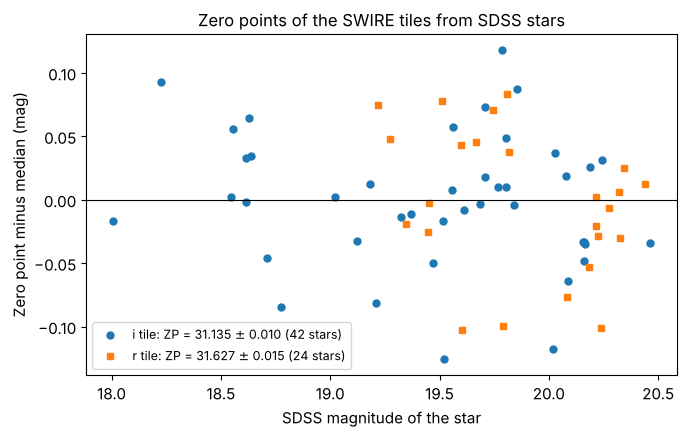

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for band, mk in (("i", "o"), ("r", "s")):
    st = zp_stars[band]; u = st["used"]
    ax.plot(st["m_sdss"][u], st["zp"][u] - zp[band]["ZP"], mk, ms=5, label=f"{band} tile: ZP = {zp[band]['ZP']:.3f} $\\pm$ {zp[band]['err']:.3f} ({u.sum()} stars)")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("SDSS magnitude of the star"); ax.set_ylabel("Zero point minus median (mag)")
ax.set_title("Zero points of the SWIRE tiles from SDSS stars"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "08_tile_zero_points.png"); plt.show()

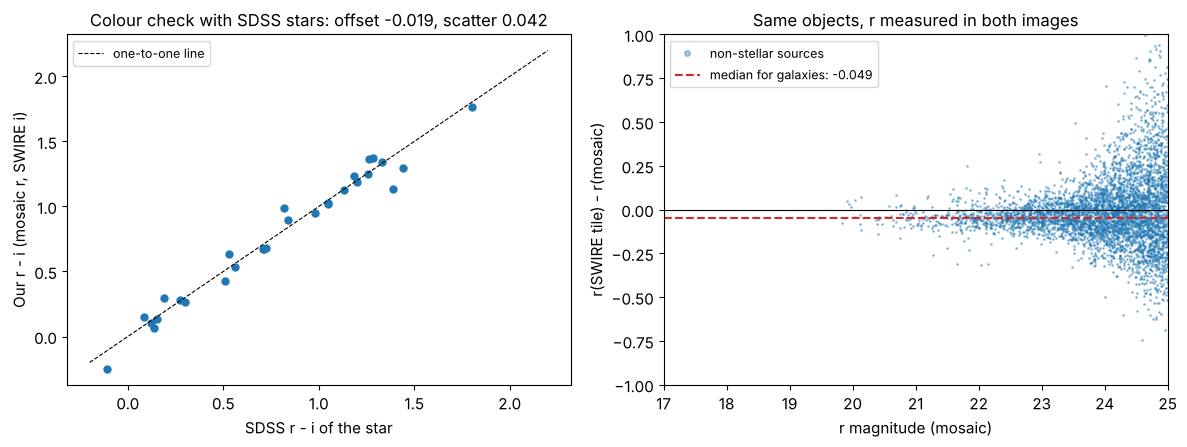

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(sd_ri, our_ri, "o", ms=5)
xx_ = np.linspace(-0.2, 2.2, 10); axes[0].plot(xx_, xx_, "k--", lw=0.8, label="one-to-one line")
axes[0].set_xlabel("SDSS r - i of the star"); axes[0].set_ylabel("Our r - i (mosaic r, SWIRE i)")
axes[0].set_title(f"Colour check with SDSS stars: offset {off_med:+.3f}, scatter {off_sig:.3f}"); axes[0].legend()
b = (col["flag_r"] == 0) & (col["flag_r_tile"] == 0) & np.isfinite(col["r_tile_ap"]) & (col["class"] != "star")
axes[1].plot(col["r_ap"][b], (col["r_tile_ap"] - col["r_ap"])[b], ".", ms=2, alpha=0.4, color="C0", label="non-stellar sources")
axes[1].axhline(0, color="k", lw=0.8); axes[1].axhline(res_b["galaxies"][0], color="C3", ls="--", label=f"median for galaxies: {res_b['galaxies'][0]:+.3f}")
axes[1].set_ylim(-1, 1); axes[1].set_xlim(17, 25)
axes[1].set_xlabel("r magnitude (mosaic)"); axes[1].set_ylabel("r(SWIRE tile) - r(mosaic)")
axes[1].set_title("Same objects, r measured in both images"); axes[1].legend(markerscale=4)
fig.tight_layout(); fig.savefig(FIG / "08_colour_checks.png"); plt.show()